# SESI 8 | Analisis Teks dan Sentimen dengan Kriteria Terdefinisi
## NusaMart Customer Review Challenge


**Cara menggunakan:** BACA kasus → IKUTI petunjuk → KLIK ▶ Run pada kode tepat di bawahnya → BACA hasil dan artinya → LANJUT.

- Kamu **tidak perlu menulis/mengedit Python atau SQL**. Jangan mengganti isi cell kode.
- **Cell Notebook** = bagian dengan tombol ▶ Run. **Sel Excel** = kotak seperti `C12` pada Working Paper.
- Jika muncul **STOP**, baca pesan perbaikan dan minta bantuan trainer. Jangan melewati pemeriksaan.


## 00. Hubungan Sesi 7 → Sesi 8 dan Studi Kasus

### Apa yang sudah kita lakukan pada Sesi 7?
Di **Sesi 7**, kamu menguji **lima hipotesis bisnis NusaMart (H1–H5)** menggunakan angka. Kamu memeriksa besar perbedaan, kemungkinan bias, dan menghitung ulang beberapa angka di Excel sebelum memutuskan apakah temuan **SAH, GUGUR, atau TAHAN**.

### Sekarang apa yang kita lakukan pada Sesi 8?
Di **Sesi 8**, pertanyaannya berubah dari **"Apakah temuan angka bisa dipercaya?"** menjadi **"Apakah label sentimen buatan AI bisa dipercaya?"**. Prinsipnya sama: **hasil AI perlu diperiksa dengan bukti, bukan langsung diterima.**

### Studi kasus: 500 ulasan pelanggan NusaMart
NusaMart mendapat 500 ulasan pelanggan tentang produk, pembayaran, pengiriman, dan pelayanan. Tim bisnis ingin mengelompokkan ulasan menjadi **POSITIVE** (pujian), **NEUTRAL** (informasi), atau **NEGATIVE** (keluhan). Membaca 500 teks manual memakan waktu, tetapi AI juga bisa keliru mengenali **sindiran** dan keluhan yang bercampur pujian.

**Peran kamu:** Data Analyst NusaMart.

**Misi kamu:** (1) gunakan **Coding Scheme dan empat Few-Shot terstandar** untuk memandu Agent, (2) isi **25 label manual tanpa melihat jawaban AI**, (3) minta Antigravity mengklasifikasikan **500 ulasan**, (4) bandingkan hasil dengan audit, (5) jelaskan **satu perbaikan** berdasarkan bukti.

### Analogi: menyortir 500 surat ke tiga kotak
- **Coding Scheme** = aturan kotak mana untuk sebuah surat.
- **Few-Shot** = contoh surat yang telah dilabeli agar Agent tahu polanya.
- **AI Agent** = asisten yang menyortir 500 surat.
- **Audit manual 25** = kamu mengecek sendiri sejumlah surat **sebelum melihat jawaban asisten**.
- **Confusion Matrix** = peta kotak mana yang paling sering tertukar.

**Catatan urutan:** Untuk menjaga independensi, **audit manual dilakukan lebih dahulu**, baru hasil label Agent diperlihatkan. Ini tidak mengubah konsep analisis sentimen yang dipelajari.

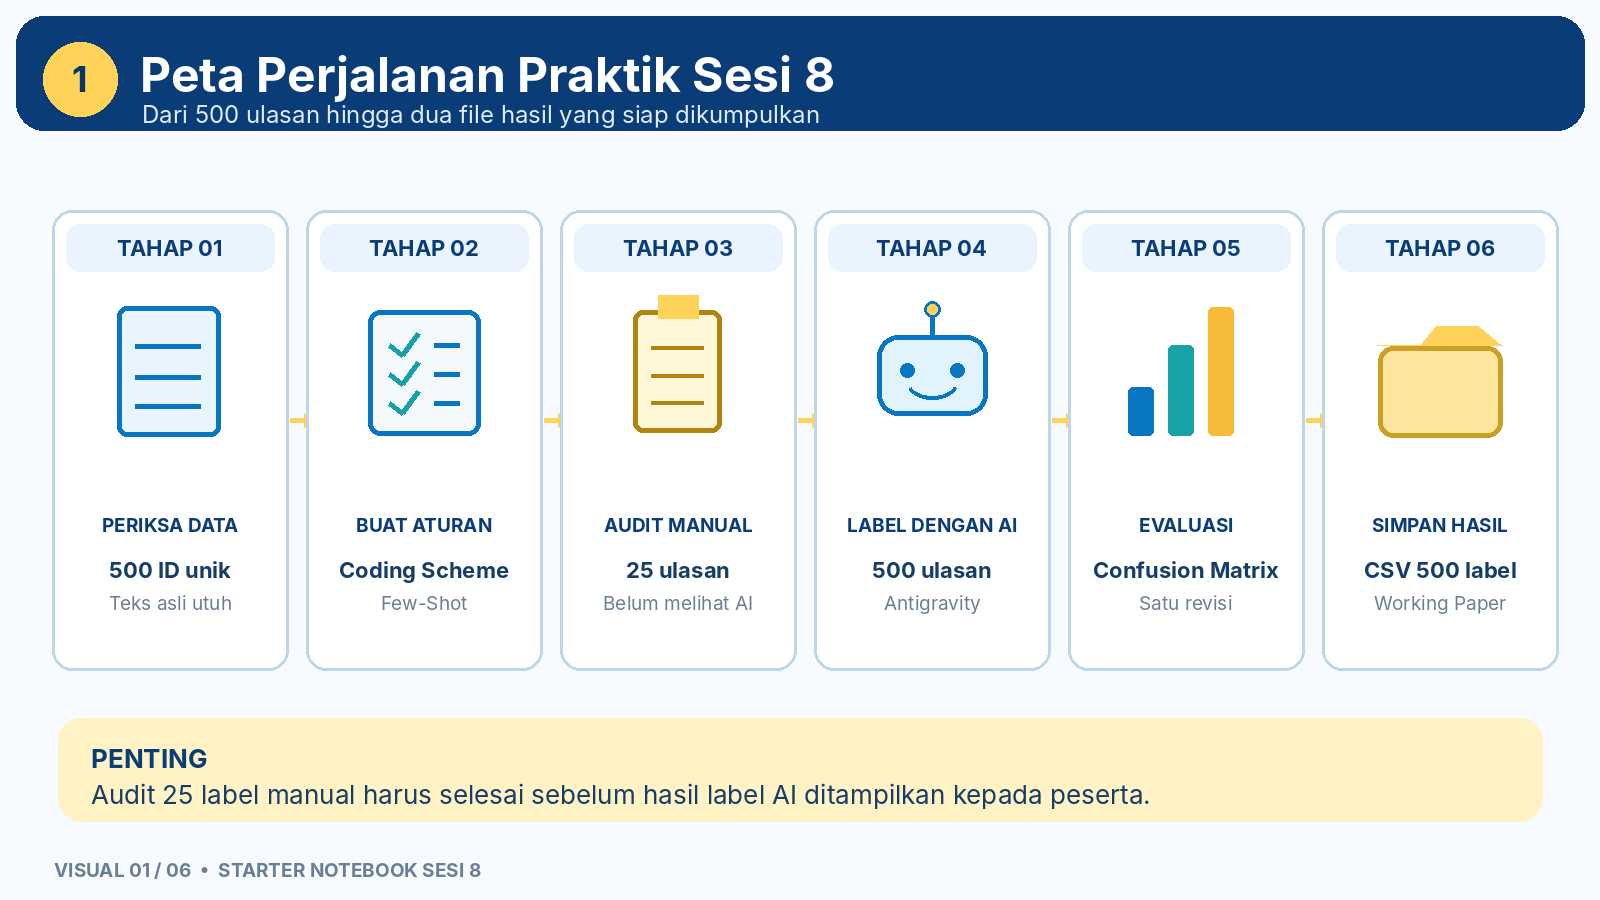

### Glosarium — istilah yang akan dipakai

| Istilah | Arti sederhana |
|---|---|
| **Dataset / CSV** | Tabel berisi seluruh ulasan pelanggan. |
| **Review ID** | Nomor identitas unik setiap ulasan. |
| **Original Text** | Ulasan asli dari pelanggan, tidak boleh diubah. |
| **Clean Text** | Salinan teks yang dirapikan, tidak menghilangkan makna/negasi. |
| **Preprocessing** | Menyiapkan teks agar lebih mudah diproses. |
| **Sentiment Label** | Kategori POSITIVE, NEUTRAL, atau NEGATIVE. |
| **Coding Scheme** | Aturan untuk menentukan tiga kategori tersebut. |
| **Few-Shot** | Contoh ulasan dan labelnya untuk membantu mengarahkan AI. |
| **Prompt** | Instruksi yang dikirim ke AI Agent. **Notebook membuat prompt, kamu mengirimkannya.** |
| **Antigravity / AI Agent** | Asisten AI untuk memproses dan mengelompokkan 500 ulasan. |
| **Audit Manual** | Memilih sendiri label untuk 25 ulasan tanpa melihat label Agent. |
| **Confusion Matrix** | Tabel hasil perbandingan label manual dengan label AI. |
| **MATCH / MISMATCH** | Cocok / berbeda antara dua label untuk satu Review ID. |
| **Gate / STOP / PASS** | Pemeriksaan yang menentukan apakah boleh lanjut. STOP berarti ada bagian yang perlu diperbaiki. |
| **Notebook cell / Run** | Bagian berisi kode dengan tombol ▶ untuk menjalankan satu tahapan. |
| **Sel Excel** | Kotak pada lembar kerja, misalnya `C12` di Sheet `01 Audit 25`. |

**Ingat:** status `PASS` pada format 500 label **belum** berarti akurasi 100%.

## 01. Siapkan Workspace: file apa yang harus dibuka?

**Kasus:** Tim NusaMart ingin menganalisis sumber ulasan yang sama. Jika file salah folder, hasil tidak bisa dibandingkan.

**Tujuan:** Notebook menemukan dataset dan Working Paper yang benar tanpa kamu mengetik lokasi file.

**Ikuti bersama trainer:**
1. Buka **Antigravity / VS Code**.
2. Klik **File → Open Folder**, pilih proyek **`Bootcamp_Data_Analyst`** yang kamu gunakan pada sesi sebelumnya.
3. Buka folder **`practice/sesi_08/`**.
4. Pastikan tiga file **di folder yang sama**: `reviews_500.csv`, `S8_NusaMart_Text_Sentiment_Working_Paper.xlsx`, dan `S8_NusaMart_Text_Sentiment_Starter.ipynb`.
5. Klik dua kali file Starter `.ipynb` untuk membuka Notebook.
6. Pilih kernel Python yang digunakan di kelas sebelumnya jika aplikasi memintanya.

**Jangan** membuat proyek baru, mengganti nama file, atau mengubah CSV. Folder `outputs/sesi_08/` akan dibuat otomatis.

**Berikutnya:** Jalankan **LANGKAH 01 — Menyalakan Mesin**, kemudian **LANGKAH 02 — Workspace Check**.

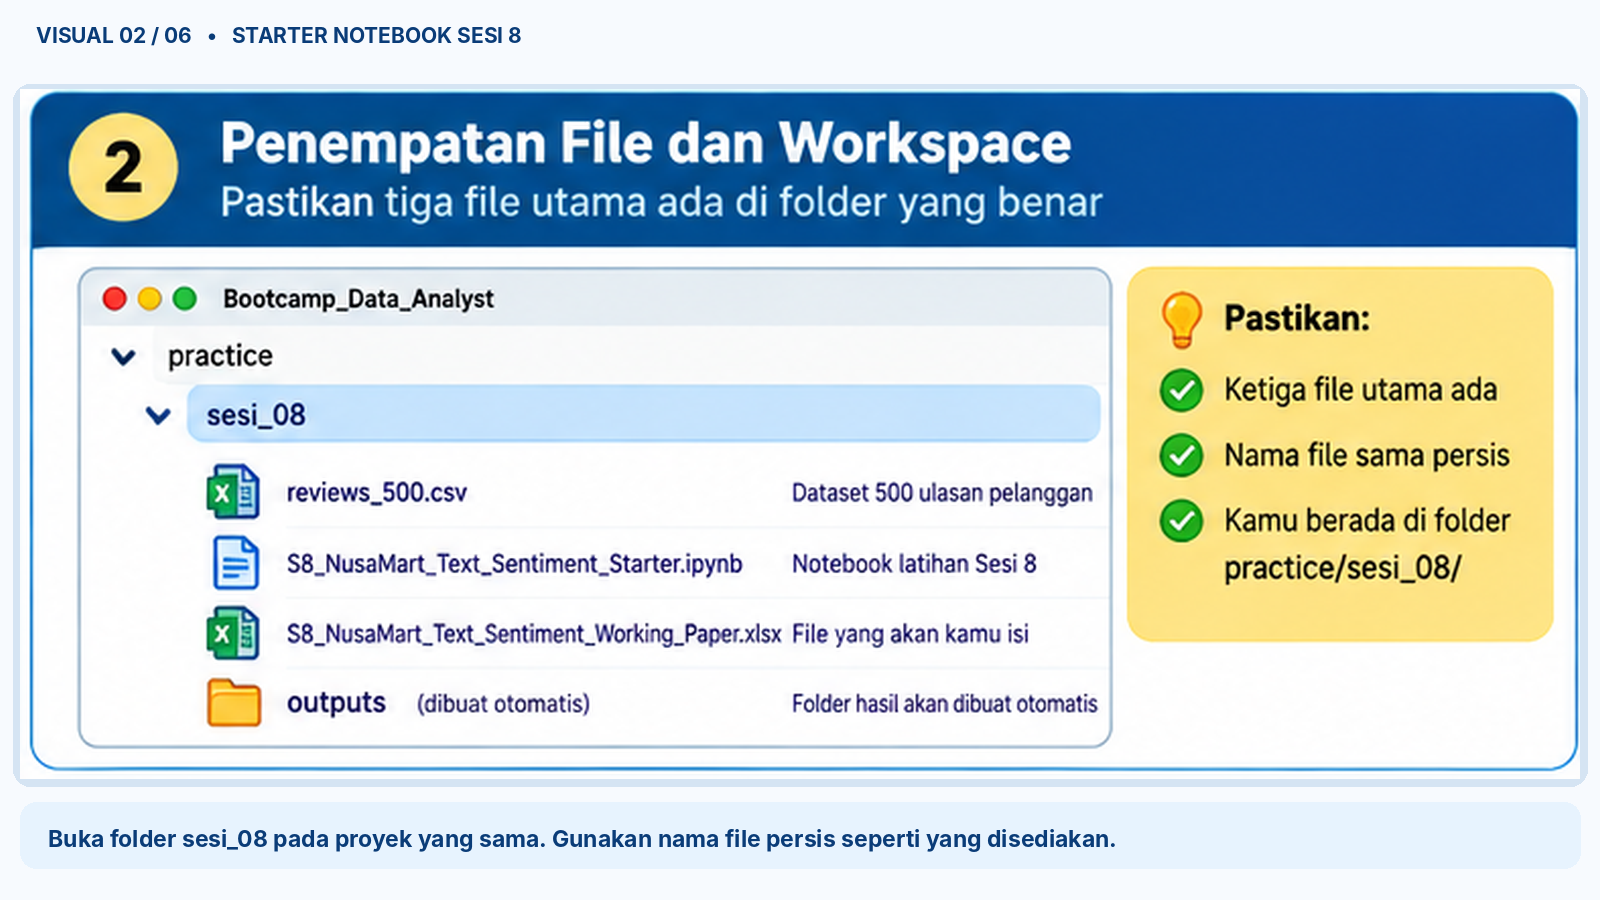

### LANGKAH 01 — Nyalakan Mesin Praktik

**Kasus:** Seperti menyalakan mesin sortir surat, kita perlu menyiapkan alat yang akan digunakan sepanjang praktik.

**Tujuan:** Menyiapkan fungsi pemeriksaan, bukan belajar sintaks Python.

**Apa yang kamu klik?** Klik ▶ **Run** pada cell kode **tepat di bawah panduan ini** (dimulai dengan `# === MESIN STARTER S8`). **Jangan mengedit kode.**

**Hasil yang diharapkan:** `MESIN STARTER: SIAP`.

**Apa artinya?** Notebook siap membantu peserta menjalankan pemeriksaan.

**Lanjut:** Scroll sedikit ke **LANGKAH 02 — Periksa Lokasi File**, klik ▶ Run pada kode berikutnya.

In [1]:
# === MESIN STARTER S8: KODE SUDAH DISIAPKAN, TIDAK PERLU DIEDIT ===
from pathlib import Path
from collections import Counter
from datetime import datetime
import hashlib, json, re, shutil, textwrap
import pandas as pd
try:
    from openpyxl import load_workbook
    from openpyxl.workbook.properties import CalcProperties
except ImportError:
    raise RuntimeError("Paket Excel belum tersedia. Minta trainer membantu memasang openpyxl pada kernel Python yang digunakan.")
from IPython.display import display

LABELS=("POSITIVE","NEUTRAL","NEGATIVE")
DATA_NAME="reviews_500.csv"
WP_NAME="S8_NusaMart_Text_Sentiment_Working_Paper.xlsx"
NOTEBOOK_NAME="S8_NusaMart_Text_Sentiment_Starter.ipynb"
SOURCE_COLS=["review_id","review_date","sales_channel","city_group","product_category","original_text"]
ST={"CHECKS":{},"AUDIT_SNAPSHOT":None,"AUDIT_READY":False}

class TahapBelumSiap(Exception): pass

def info(msg): print(msg)
def stop(msg): raise TahapBelumSiap(msg)
def require(stage):
    if not ST["CHECKS"].get(stage,False):
        stop(f"Selesaikan LANGKAH sebelumnya ({stage}) sampai PASS/READY, kemudian klik Run ulang di sini.")
def run_step(name,fn):
    print("="*66);print(f"{name}");print("="*66)
    try:
        fn()
        ST["CHECKS"][name]=True
    except Exception as exc:
        ST["CHECKS"][name]=False
        print("\n⛔ STOP / BELUM SIAP")
        if isinstance(exc,TahapBelumSiap): print(str(exc))
        else:
            print("Terjadi kendala yang belum dikenali:",str(exc)[:400])
            print("Jangan mengubah kode. Tunjukkan pesan ini kepada trainer.")
        print("Perbaiki sesuai petunjuk, lalu klik ▶ Run ulang pada LANGKAH INI.")
    print("="*66)

def locate_home():
    cwd=Path.cwd().resolve()
    trials=[cwd,cwd/'practice'/'sesi_08',cwd/'sesi_08']
    for par in list(cwd.parents)[:4]:
        trials.extend([par/'practice'/'sesi_08',par/'sesi_08'])
    for folder in trials:
        if (folder/DATA_NAME).is_file() and (folder/WP_NAME).is_file():return folder
    stop("Belum menemukan reviews_500.csv dan Working Paper S8 di folder yang sama. Buka proyek Bootcamp_Data_Analyst, lalu taruh keduanya di practice/sesi_08/.")

def wp_load(data_only=False):
    return load_workbook(ST['WP_PATH'],data_only=data_only)

def text(v): return str(v).strip() if v is not None else ''
def label(v): return text(v).upper()
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def get_audit(wb):
    # Ultra Simple: 01 Audit 25, kolom A ID, B teks asli, C label manual.
    ws=wb['01 Audit 25']
    return [(text(ws[f'A{r}'].value),text(ws[f'B{r}'].value),label(ws[f'C{r}'].value)) for r in range(12,37)]

def audit_snapshot(audit):
    return hashlib.sha256(json.dumps(audit,ensure_ascii=False).encode('utf-8')).hexdigest()

def audit_validate(wb,need_labels=True):
    require('LANGKAH 03 | Dataset')
    rows=get_audit(wb)
    ids=[x[0] for x in rows]
    if len(rows)!=25 or len(set(ids))!=25 or any(not i for i in ids):
        stop('Sheet 01 Audit 25: harus ada 25 Review ID unik di A12:A36. Jangan mengganti atau menyortir data audit.')
    original=ST['SOURCE'].set_index('review_id')['original_text']
    diffs=[rid for rid,raw,lab in rows if rid not in original.index or text(raw)!=text(original.loc[rid])]
    if diffs:
        stop(f'Sheet 01 Audit 25: Review ID/teks asli tidak cocok dengan CSV: {diffs[:5]}. Gunakan template Working Paper yang sesuai reviews_500.csv.')
    if need_labels:
        invalid=[r for r in range(12,37) if label(wb['01 Audit 25'][f'C{r}'].value) not in LABELS]
        if invalid: stop(f'Sheet 01 Audit 25: {25-len(invalid)}/25 sudah valid. Isi dropdown yang kosong/salah pada C{invalid[0]}' + (f' sampai C{invalid[-1]}' if len(invalid)>1 else '') + '. Pilih POSITIVE, NEUTRAL, atau NEGATIVE. Ctrl+S lalu Run ulang.')
    return rows

# Aturan dan empat Few-Shot TERSTANDAR: tidak lagi diisi pada Excel.
RULES_VERSION='S8-CS-01'
FEWSHOT_VERSION='S8-FS-01'
STANDARD_RULES={
 'definitions':[
   ('POSITIVE','Ulasan mengungkapkan pujian, kepuasan, atau pengalaman baik dalam belanja.'),
   ('NEUTRAL','Ulasan menyampaikan fakta/informasi tanpa pujian atau keluhan dominan.'),
   ('NEGATIVE','Ulasan mengungkapkan keluhan, ketidakpuasan, atau pengalaman buruk.')],
 'difficult':[
   ('R-01','Sarkasme','Utamakan maksud sindiran dan konteks keluhan, bukan kata pujian secara literal.'),
   ('R-02','Emoji bertentangan','Utamakan makna kalimat dan konteks; emoji saja tidak menentukan label.'),
   ('R-03','Banyak aspek','Pilih sentimen dominan berdasarkan isi keseluruhan; jika tidak jelas, pilih NEUTRAL secara hati-hati.')],
 'fewshot':[
   ('Produknya sesuai foto, saya puas.','POSITIVE','Coding Scheme'),
   ('Paket dikirim pukul 10.00 pagi.','NEUTRAL','Coding Scheme'),
   ('Barang rusak saat diterima.','NEGATIVE','Coding Scheme'),
   ('Mantap, aplikasi error lagi!','NEGATIVE','R-01 sarkasme')]
}

def friendly_status():
    return ', '.join(k.split(' | ')[0] for k,v in ST['CHECKS'].items() if v)
print('✅ MESIN STARTER: SIAP. Tidak perlu mengubah kode. Lanjut ke LANGKAH 02.')

✅ MESIN STARTER: SIAP. Tidak perlu mengubah kode. Lanjut ke LANGKAH 02.


### LANGKAH 02 — Periksa Lokasi File

**Kasus:** Notebook harus menemukan berkas sumber 500 ulasan dan formulir audit yang cocok.

**Tujuan:** Menghindari error karena folder atau nama file berbeda.

**Apa yang kamu klik?** Klik ▶ **Run** pada cell kode tepat di bawah instruksi ini (dimulai `def step_workspace`). Tidak perlu mengetik path.

**Hasil contoh:** `WORKSPACE CHECK: PASS` dengan `Dataset: FOUND` dan `Working Paper: FOUND`.

**Apa artinya?** Dua file input ditemukan. **Belum** berarti semua isi data valid.

**Jika STOP:** lihat lokasi yang dicetak dan pastikan ketiga file ada di `practice/sesi_08/`.

**Lanjut:** Periksa isi 500 ulasan pada LANGKAH 03.

In [5]:
def step_workspace():
    home=locate_home()
    ST['HOME']=home
    ST['SOURCE_PATH']=home/DATA_NAME
    ST['WP_PATH']=home/WP_NAME
    ST['OUT_DIR']=home/'outputs'/'sesi_08'
    ST['OUT_DIR'].mkdir(parents=True,exist_ok=True)
    print('✅ WORKSPACE CHECK: PASS')
    print('Folder S8       :',home)
    print('Dataset         : FOUND')
    print('Working Paper   : FOUND')
    print('Folder output   : READY')
    print('Berikutnya: LANGKAH 03, periksa dataset NusaMart.')
run_step('LANGKAH 02 | Workspace',step_workspace)

LANGKAH 02 | Workspace
✅ WORKSPACE CHECK: PASS
Folder S8       : C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_08
Dataset         : FOUND
Working Paper   : FOUND
Folder output   : READY
Berikutnya: LANGKAH 03, periksa dataset NusaMart.


## 02. Periksa Dataset NusaMart — LANGKAH 03

**Kasus:** Kalau jumlah surat kurang atau ID berulang, hasil klasifikasi NusaMart bisa salah.

**Tujuan:** Memastikan dataset sumber berisi **500 ulasan dengan 500 Review ID unik** dan tidak ada teks kosong.

**Apa yang kamu klik?** Klik ▶ **Run** pada cell kode tepat di bawah ini (dimulai `def step_dataset`). **Tidak perlu membuka Excel atau mengedit Python.**

**Hasil yang diharapkan:** `SOURCE INTEGRITY GATE: PASS` dengan tabel 500 data, 500 ID unik, 0 teks kosong.

**Apa artinya?** Data sumber siap digunakan. Label sentimen belum dihitung pada langkah ini.

**Jika STOP:** unduh ulang `reviews_500.csv` yang benar dari bahan kelas, jangan menghapus baris.

**Lanjut:** LANGKAH 04 — Siapkan teks tanpa mengubah makna.

In [6]:
def step_dataset():
    require('LANGKAH 02 | Workspace')
    df=pd.read_csv(ST['SOURCE_PATH'],encoding='utf-8-sig',dtype={'review_id':'string'},keep_default_na=False)
    missing=[x for x in SOURCE_COLS if x not in df.columns]
    if missing:stop('Kolom dataset tidak lengkap: '+', '.join(missing))
    if len(df)!=500:stop(f'Jumlah ulasan {len(df)}, seharusnya 500. Gunakan reviews_500.csv dari LMS S8.')
    df['review_id']=df['review_id'].astype(str).str.strip()
    if df['review_id'].nunique()!=500 or df['review_id'].eq('').any():stop('review_id kosong atau duplikat. Periksa CSV sumber dari LMS.')
    if df['original_text'].astype(str).str.strip().eq('').any():stop('Ada original_text kosong. Periksa CSV sumber, jangan hapus baris.')
    ST['SOURCE']=df.copy(deep=True)
    ST['SOURCE_SHA']=sha(ST['SOURCE_PATH'])
    print('✅ SOURCE INTEGRITY GATE: PASS')
    display(pd.DataFrame({'Pemeriksaan':['Jumlah ulasan','Review ID unik','Original Text kosong'],
       'Hasil':[len(df),df['review_id'].nunique(),int(df['original_text'].astype(str).str.strip().eq('').sum())],
       'Target':[500,500,0]}))
    print('Teks asli tidak diubah. Berikutnya: LANGKAH 04, persiapan teks.')
run_step('LANGKAH 03 | Dataset',step_dataset)

LANGKAH 03 | Dataset
✅ SOURCE INTEGRITY GATE: PASS


,Pemeriksaan,Hasil,Target
0,Jumlah ulasan,500,500
1,Review ID unik,500,500
2,Original Text kosong,0,0


Teks asli tidak diubah. Berikutnya: LANGKAH 04, persiapan teks.


## 03. Siapkan Teks Tanpa Menghapus Maknanya — LANGKAH 04

**Kasus:** Beberapa surat mengandung URL, spasi berlebih, atau pengulangan teks. Kita boleh merapikan **salinan teks kerja**, tetapi tidak boleh menghapus keluhan, kata **tidak**, dan emoji penting.

**Analogi:** Membersihkan stiker pada amplop tanpa menghilangkan isi surat.

**Tujuan:** Menghasilkan `clean_text` dari `original_text` sambil menjaga sumber aslinya.

**Apa yang kamu klik?** Klik ▶ **Run** pada cell kode tepat di bawah visual ini (dimulai `def step_prepare`).

**Hasil contoh:** `TEXT PREPARATION: PASS`, jumlah 500, Original Text preserved = True, dan contoh sebelum/sesudah.

**Apa artinya?** Teks kerja siap diklasifikasi. Baris dengan isi teks mirip/duplikat **tetap dipertahankan** karena memiliki Review ID masing-masing.

**Lanjut:** Pelajari aturan Coding Scheme/Few-Shot pada LANGKAH 05 (tanpa membuka Excel).

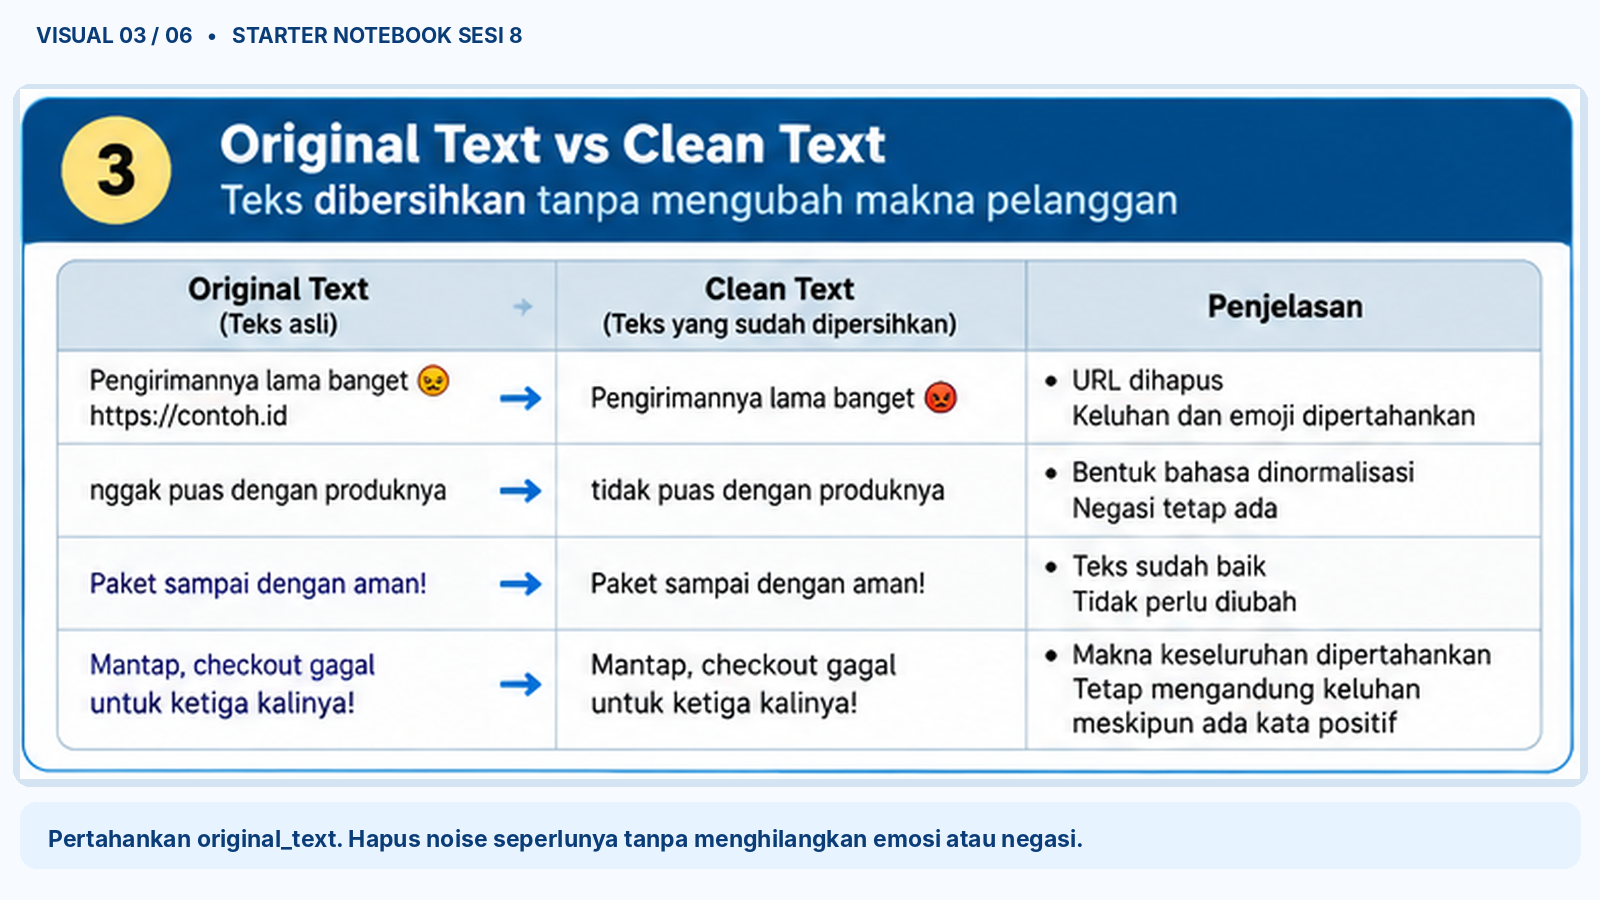

In [7]:
def step_prepare():
    require('LANGKAH 03 | Dataset')
    w=ST['SOURCE'].copy(deep=True)
    url_re=re.compile(r'https?://\S+|www\.\S+',flags=re.IGNORECASE)
    def tidy(t):return re.sub(r'\s+',' ',url_re.sub('',str(t))).strip()
    w['clean_text']=w['original_text'].map(tidy)
    w['is_exact_duplicate']=w['original_text'].duplicated(keep='first')
    if w['clean_text'].eq('').any():stop('Ada clean_text kosong sesudah persiapan. Tampilkan ke trainer sebelum lanjut.')
    ST['WORKING']=w
    print('✅ TEXT PREPARATION: PASS')
    print('Total ulasan     :',len(w))
    print('Original preserved :',bool(w['original_text'].equals(ST['SOURCE']['original_text'])))
    print('Duplicate beyond first:',int(w['is_exact_duplicate'].sum()))
    display(w[['review_id','original_text','clean_text']].head(3))
    print('Berikutnya: baca aturan sentimen standar di Bagian 04, lalu LANGKAH 05.')
run_step('LANGKAH 04 | Prepare',step_prepare)

LANGKAH 04 | Prepare
✅ TEXT PREPARATION: PASS
Total ulasan     : 500
Original preserved : True
Duplicate beyond first: 20


,review_id,original_text,clean_text
0,R0001,"Sudah bayar tetapi pesanan dibatalkan, tolong ...","Sudah bayar tetapi pesanan dibatalkan, tolong ..."
1,R0002,"Pengiriman cepat dan paket sampai dengan aman,...","Pengiriman cepat dan paket sampai dengan aman,..."
2,R0003,"Pengiriman terlambat dari estimasi, sangat men...","Pengiriman terlambat dari estimasi, sangat men..."


Berikutnya: baca aturan sentimen standar di Bagian 04, lalu LANGKAH 05.


## 04. Kenali Coding Scheme & Few-Shot Terstandar — LANGKAH 05

**Hubungan dengan kasus:** Untuk memilah 500 ulasan, Agent harus mendapat aturan yang konsisten agar tidak keliru menafsirkan kata-kata seperti "mantap" dalam sebuah keluhan.

**Tujuan:** Kamu **mengenali, menerapkan, dan memeriksa** aturan yang disediakan.

### Coding Scheme S8-CS-01 — kapan sebuah label dipakai?
| Label | Aturan praktis |
|---|---|
| **POSITIVE** | Pujian atau kepuasan terhadap produk dan pengalaman belanja. |
| **NEUTRAL** | Informasi/fakta transaksi tanpa pujian atau keluhan dominan. |
| **NEGATIVE** | Keluhan, ketidakpuasan, atau pengalaman buruk. |

**Kasus sulit:** (1) **Sarkasme**: utamakan maksud sindiran, bukan kata pujian. (2) **Emoji bertentangan**: baca keseluruhan kalimat, bukan emoji saja. (3) **Multi-aspek**: pilih sentimen dominan, bila tidak dapat ditetapkan gunakan NEUTRAL dan jelaskan keterbatasan bila relevan.

### Four Few-Shot S8-FS-01 — contoh untuk AI
| Teks contoh (sintetis, bukan sampel audit) | Label yang tepat | Mengapa? |
|---|---|---|
| Produk sesuai foto, saya puas. | POSITIVE | Ada kepuasan. |
| Paket dikirim pukul 10 pagi. | NEUTRAL | Hanya informasi. |
| Barang rusak saat diterima. | NEGATIVE | Ada keluhan. |
| Mantap, aplikasi error lagi! | NEGATIVE | Sindiran terhadap masalah. |

### Sekarang periksa pemahamanmu
1. **Tidak perlu membuka atau mengisi Excel untuk LANGKAH 05.**
2. Klik ▶ **Run** pada kode setelah visual ini (dimulai `def step_rules`).
3. Ketika muncul kotak input, jawab label untuk contoh baru: **`Wah cepat sekali, paket datang dua minggu terlambat!`**. Ketik salah satu: POSITIVE / NEUTRAL / NEGATIVE, lalu Enter.
4. Jika keliru, baca aturan sarkasme dan jalankan ulang. Trainer akan menjelaskan mengapa labelnya tepat.

**Hasil yang diharapkan:** `CODING SCHEME: READY | FEW-SHOT: READY`.

**Apa artinya?** Kamu sudah menggunakan aturan terstandar S8-CS-01 dan contoh S8-FS-01. Keduanya akan dimasukkan **secara otomatis** ke prompt untuk Agent.

**Lanjut:** Buka Excel untuk audit manual 25 ulasan.

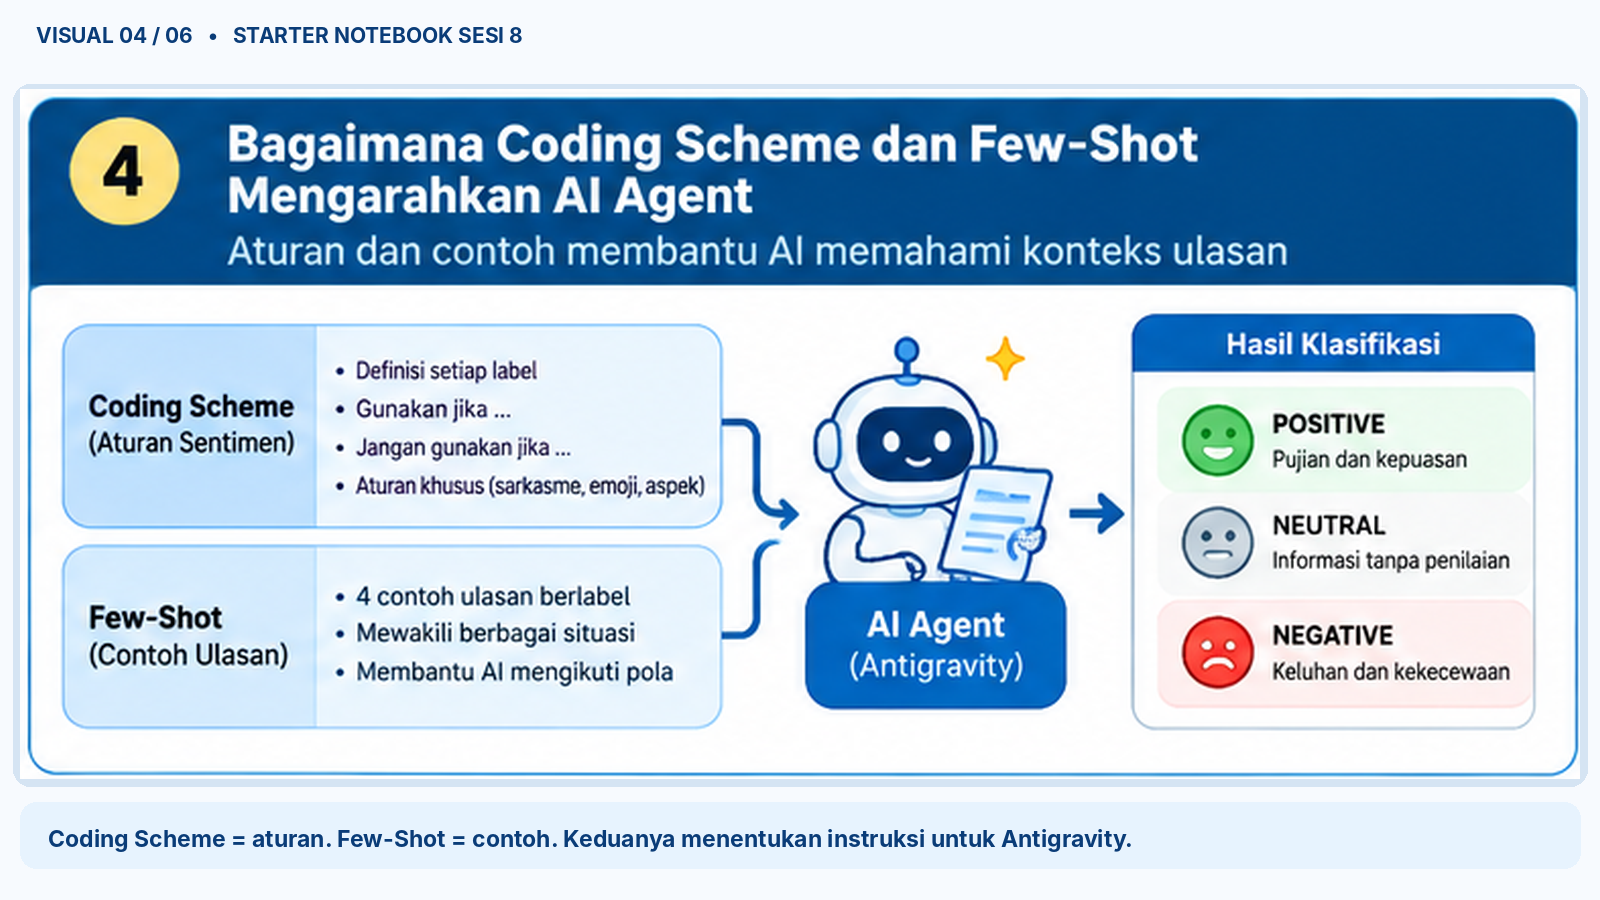

In [8]:
def step_rules():
    require('LANGKAH 04 | Prepare')
    print('PERIKSA PEMAHAMAN:')
    print('"Wah cepat sekali, paket datang dua minggu terlambat!"')
    print('Pilihan: POSITIVE / NEUTRAL / NEGATIVE. Ketik salah satu, lalu Enter.')
    jawaban=label(input('Label menurutmu: '))
    if jawaban not in LABELS:
        stop('Ketik hanya POSITIVE, NEUTRAL, atau NEGATIVE, lalu Run ulang LANGKAH 05.')
    if jawaban!='NEGATIVE':
        stop('Coba baca kembali aturan sarkasme. Maksud keseluruhan adalah keluhan tentang pengiriman terlambat. Ulangi LANGKAH 05.')
    ST['RULES']={k:list(v) for k,v in STANDARD_RULES.items()}
    ST['RULES_VERSION']=RULES_VERSION
    ST['FEWSHOT_VERSION']=FEWSHOT_VERSION
    ST['RULES_REVIEW']=jawaban
    print('✅ CODING SCHEME: READY | FEW-SHOT: READY')
    print('Jawaban pemeriksaan:',jawaban,'— benar karena kalimat menyindir pengiriman terlambat.')
    display(pd.DataFrame(ST['RULES']['definitions'],columns=['Label','Aturan standar']))
    display(pd.DataFrame(ST['RULES']['fewshot'],columns=['Teks Few-Shot','Label','Dasar aturan']))
    print('Versi aturan:',RULES_VERSION,'| Versi Few-Shot:',FEWSHOT_VERSION)
    print('Berikutnya: buka Excel Sheet 01 Audit 25, isi hanya C12:C36.')
run_step('LANGKAH 05 | Rules',step_rules)

LANGKAH 05 | Rules
PERIKSA PEMAHAMAN:
"Wah cepat sekali, paket datang dua minggu terlambat!"
Pilihan: POSITIVE / NEUTRAL / NEGATIVE. Ketik salah satu, lalu Enter.
✅ CODING SCHEME: READY | FEW-SHOT: READY
Jawaban pemeriksaan: NEGATIVE — benar karena kalimat menyindir pengiriman terlambat.


,Label,Aturan standar
0,POSITIVE,"Ulasan mengungkapkan pujian, kepuasan, atau pe..."
1,NEUTRAL,Ulasan menyampaikan fakta/informasi tanpa puji...
2,NEGATIVE,"Ulasan mengungkapkan keluhan, ketidakpuasan, a..."


,Teks Few-Shot,Label,Dasar aturan
0,"Produknya sesuai foto, saya puas.",POSITIVE,Coding Scheme
1,Paket dikirim pukul 10.00 pagi.,NEUTRAL,Coding Scheme
2,Barang rusak saat diterima.,NEGATIVE,Coding Scheme
3,"Mantap, aplikasi error lagi!",NEGATIVE,R-01 sarkasme


Versi aturan: S8-CS-01 | Versi Few-Shot: S8-FS-01
Berikutnya: buka Excel Sheet 01 Audit 25, isi hanya C12:C36.


## 05. Audit Manual 25 Ulasan — LANGKAH 06 | **Working Paper Sheet 01**

**Kasus:** Sebelum melihat jawaban Agent, kamu perlu memberi label sendiri pada 25 ulasan sebagai pembanding yang independen.

**Tujuan:** Menghasilkan 25 label manual POSITIVE/NEUTRAL/NEGATIVE yang tidak meniru AI.

### Tepatnya Excel mana yang dibuka dan diisi?
1. Di File Explorer/VS Code buka **`S8_NusaMart_Text_Sentiment_Working_Paper.xlsx`** menggunakan Microsoft Excel atau aplikasi spreadsheet yang digunakan kelas.
2. Klik tab bawah **`01 Audit 25`**. **Hanya tab ini yang kamu isi sekarang.**
3. Lihat **kolom A (`A12:A36`)** = Review ID. **Jangan diedit.**
4. Lihat **kolom B (`B12:B36`)** = teks ulasan pelanggan. **Baca, jangan diedit.**
5. Klik **sel `C12`** (kolom C, baris 12) → pilih **POSITIVE / NEUTRAL / NEGATIVE** dari dropdown setelah membaca teks pada **B12**.
6. Lanjutkan bertahap: **`C13`, `C14`, ... sampai `C36`**. Total **25 pilihan label**.
7. Lihat **`B7`** = jumlah label valid yang sudah terisi (target 25) dan **`C7`** = `AUDIT: READY`.
8. Tekan **Ctrl+S** untuk menyimpan Excel. **Jangan membuka hasil Agent terlebih dahulu.**
9. Kembali ke Notebook, klik ▶ **Run** pada kode tepat setelah visual (dimulai `def step_manual`).

**Contoh pengisian, bukan jawaban audit:** “Pengiriman cepat, saya puas.” → **POSITIVE** karena berisi pujian.

**Hasil yang diharapkan di Notebook:** `MANUAL AUDIT: READY | 25/25`.

**Apa artinya?** Label manual sudah lengkap dan **dikunci**. Jangan mengubah `C12:C36` karena kamu melihat hasil AI nanti.

**Jika STOP:** pesan Notebook menunjuk baris yang kosong/salah, misalnya `C17`. Kembali ke sel tersebut, pilih label, **Ctrl+S**, lalu Run ulang.

**Lanjut:** LANGKAH 07 — Siapkan prompt Agent.

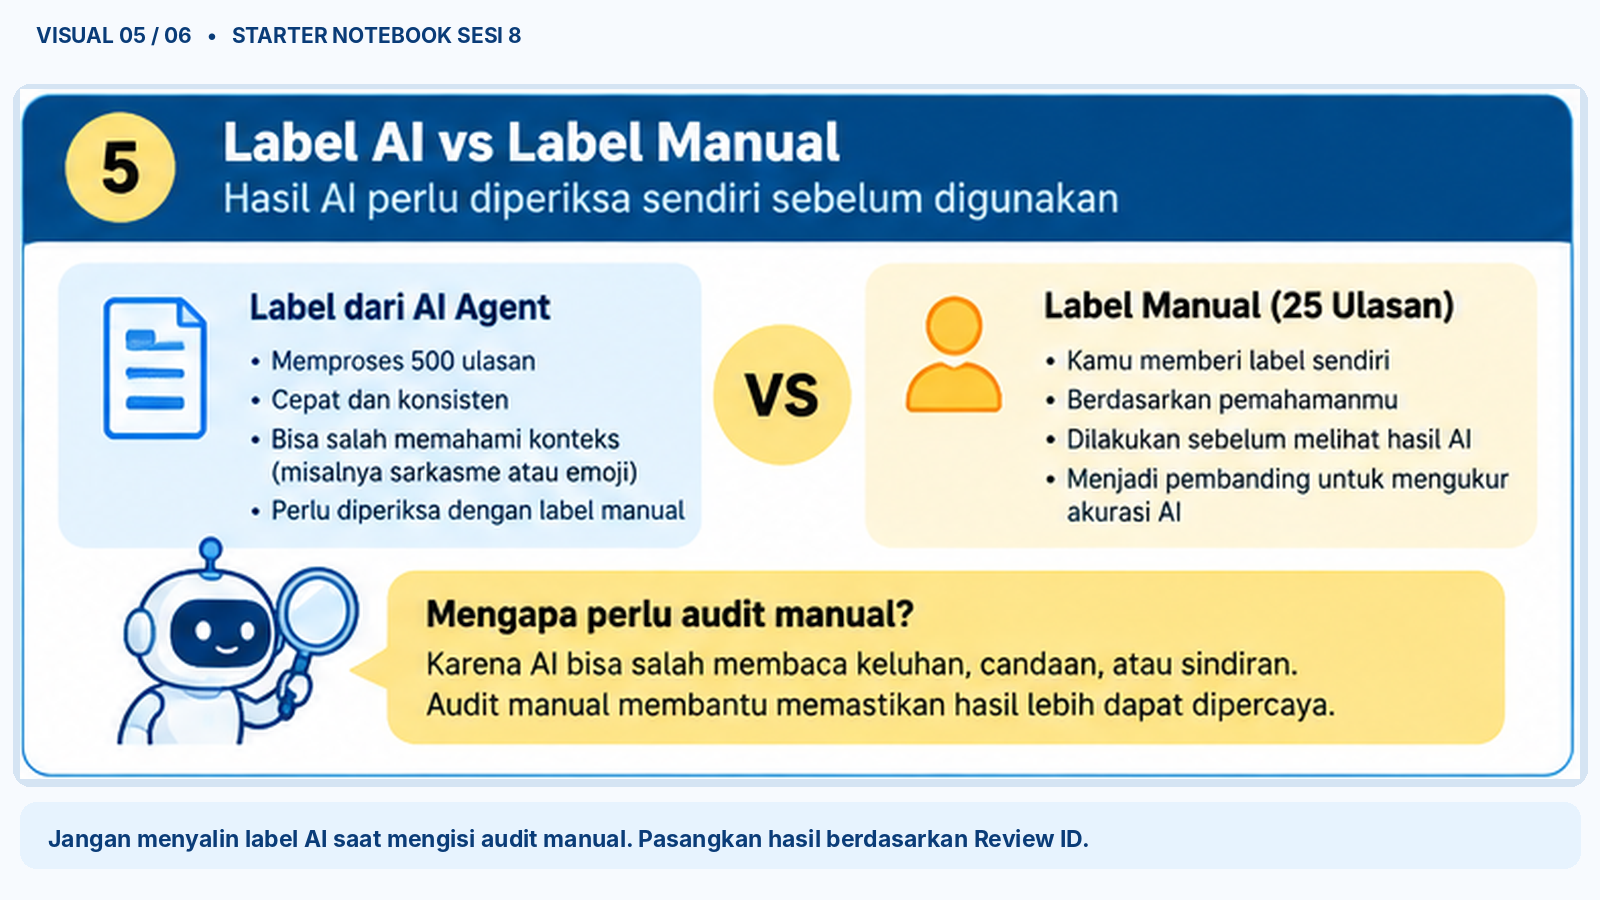

In [10]:
def step_manual():
    require('LANGKAH 05 | Rules')
    wb=wp_load()
    try: audit=audit_validate(wb,need_labels=True)
    finally:wb.close()
    ST['AUDIT']=audit
    ST['AUDIT_SNAPSHOT']=audit_snapshot(audit)
    ST['AUDIT_READY']=True
    print('✅ MANUAL AUDIT: READY | 25/25')
    print('Review ID sampel tetap:',', '.join(x[0] for x in audit[:5]),'...')
    print('Label manual DIKUNCI sebagai pembanding. Jangan diubah setelah Agent berjalan.')
    print('Berikutnya: siapkan prompt untuk Antigravity.')
run_step('LANGKAH 06 | Audit',step_manual)

LANGKAH 06 | Audit
✅ MANUAL AUDIT: READY | 25/25
Review ID sampel tetap: R0013, R0014, R0016, R0017, R0045 ...
Label manual DIKUNCI sebagai pembanding. Jangan diubah setelah Agent berjalan.
Berikutnya: siapkan prompt untuk Antigravity.


## 06. Buat Prompt Antigravity — LANGKAH 07

**Kasus:** Agent perlu tahu apa tugasnya, aturan sentimen yang digunakan, contoh label, file masukan, dan format hasil yang benar.

**Tujuan:** Menyusun instruksi yang konsisten bagi seluruh 500 ulasan tanpa mengetik prompt panjang dari nol.

### Apakah peserta harus membuat prompt sendiri?
**Tidak.** Setelah kamu klik Run, **Notebook membuat prompt otomatis** dari Coding Scheme **S8-CS-01** dan Few-Shot **S8-FS-01** yang baru kamu pelajari. **Kamu tetap perlu membaca, menyalin, lalu mengirim prompt itu ke Antigravity.** Menyiapkan prompt **tidak sama** dengan menjalankan Agent.

**Apa yang kamu klik?** Klik ▶ **Run** pada kode tepat di bawah ini (dimulai `def step_prompt`).

**Hasil yang diharapkan:** `PROMPT ANTIGRAVITY: READY`. Notebook membuat dua file otomatis pada `outputs/sesi_08/`:
1. **`agent_input_v1.csv`** — 500 Review ID dan `clean_text`. File ini **tidak memuat 25 label manual**.
2. **`S8_Prompt_Agent_Labeling.txt`** — instruksi lengkap siap dikirim ke AI.

**Apa arti hasilnya?** Bahan dan instruksi untuk Agent sudah siap. **Belum ada hasil klasifikasi 500 ulasan** sampai Agent menjalankan tugasnya.

**Jika STOP:** periksa apakah isi audit Sheet `01 Audit 25!C12:C36` telah berubah setelah dikunci. Jangan menyesuaikan label audit setelah melihat AI.

**Lanjut:** Ikuti langkah membuka Antigravity pada bagian 07.

In [11]:
def step_prompt():
    require('LANGKAH 06 | Audit')
    wb=wp_load()
    try:
        new_audit=audit_validate(wb,need_labels=True)
    finally:wb.close()
    if audit_snapshot(new_audit)!=ST['AUDIT_SNAPSHOT']:
        stop('Isi audit berubah setelah LANGKAH 06. Jangan mengubah audit setelah dikunci. Minta trainer memeriksa perubahan.')
    out=ST['OUT_DIR']
    inp=out/'agent_input_v1.csv'
    ST['WORKING'][['review_id','clean_text']].to_csv(inp,index=False,encoding='utf-8-sig')
    rule_txt='\n'.join(f'- {l}: {a}' for l,a in ST['RULES']['definitions'])
    difficult_txt='\n'.join(f'- {c} ({n}): {s}' for c,n,s in ST['RULES']['difficult'])
    shots_txt='\n'.join(f'- Teks: "{t}" => {l} (Acuan: {rule})' for t,l,rule in ST['RULES']['fewshot'])
    prompt=f'''Kamu bertugas menjadi AI Agent klasifikasi sentimen ulasan pelanggan NusaMart.
Baca file input lengkap ini pada workspace peserta: {inp.as_posix()}
Jika workspace yang terbuka adalah folder Bootcamp_Data_Analyst, gunakan path relatif practice/sesi_08/outputs/sesi_08/agent_input_v1.csv.
Jika workspace yang terbuka langsung folder sesi_08, gunakan path relatif outputs/sesi_08/agent_input_v1.csv.
File itu berisi tepat 500 baris dengan header review_id,clean_text.

TUJUAN: Beri tepat SATU label untuk SETIAP review_id berdasarkan makna keseluruhan ulasan.
HANYA LABEL YANG DIIZINKAN: POSITIVE, NEUTRAL, NEGATIVE.

CODING SCHEME TERSTANDAR S8-CS-01 (sudah dipelajari dan diperiksa peserta):
{rule_txt}

ATURAN KASUS SULIT:
{difficult_txt}

FEW-SHOT TERSTANDAR S8-FS-01 (sudah dipelajari peserta):
{shots_txt}

KETENTUAN KESELAMATAN DATA DAN OUTPUT:
1. Jangan mengubah, menghapus, menimpa, atau mengurutkan ulang CSV sumber dan Working Paper.
2. Jangan membaca Sheet 02 (audit manual) atau menggunakannya sebagai label jawaban.
3. Untuk setiap teks, pertimbangkan negasi, slang, emoji, sarkasme, dan aspek dominan.
4. Jangan membuat label baru seperti MIXED, UNKNOWN, UNCLEAR atau label kosong.
5. Proses SEMUA 500 ulasan dari file input, bukan hanya contoh pertama.
6. Simpan hasil hanya ke "{(out/'agent_labels_v1.csv').as_posix()}" (setara dengan practice/sesi_08/outputs/sesi_08/agent_labels_v1.csv dari root proyek).
7. File output harus mempunyai header TEPAT: review_id,agent_label_v1.
8. Pertahankan review_id sama persis. Satu ID hanya satu label. Tanpa penjelasan tambahan di sel label.
9. Jika proses 500 baris tidak muat sekali jalan, kerjakan bertahap (misalnya per 100 baris), lalu gabungkan menjadi SATU file final yang mencakup 500 review_id unik. Jangan mengarang baris atau melewati ID.
10. Sebelum menyatakan selesai, periksa file akhir dengan mencocokkan daftar review_id input, jumlah 500, dan allowed labels.
11. Jika tidak bisa mengakses atau menyimpan file lokal, katakan kendalanya. Jangan mengaku tugas selesai tanpa file nyata.

Setelah file benar-benar ada, tulis ringkasan: jumlah baris, jumlah ID unik, jumlah label kosong, dan lokasi file hasil.
Hasil AI akan diperiksa manusia. Jangan menyatakan 500 label sudah 100% akurat.'''
    prompt_path=out/'S8_Prompt_Agent_Labeling.txt'
    prompt_path.write_text(prompt,encoding='utf-8')
    ST['PROMPT']=prompt
    ST['PROMPT_PATH']=prompt_path
    ST['AGENT_INPUT']=inp
    print('✅ PROMPT ANTIGRAVITY: READY')
    print('File untuk Agent :',inp)
    print('File prompt      :',prompt_path)
    print('\n--- MULAI PROMPT, SALIN SEMUA TEKS DI BAWAH ---\n')
    print(prompt)
    print('\n--- AKHIR PROMPT ---')
    print('PROMPT DIBUAT NOTEBOOK. Peserta harus menyalin dan mengirimnya ke Antigravity. Berikutnya: buka panel Agent sesuai panduan Bagian 07, lalu LANGKAH 08.')
run_step('LANGKAH 07 | Prompt',step_prompt)

LANGKAH 07 | Prompt
✅ PROMPT ANTIGRAVITY: READY
File untuk Agent : C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_08\outputs\sesi_08\agent_input_v1.csv
File prompt      : C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_08\outputs\sesi_08\S8_Prompt_Agent_Labeling.txt

--- MULAI PROMPT, SALIN SEMUA TEKS DI BAWAH ---

Kamu bertugas menjadi AI Agent klasifikasi sentimen ulasan pelanggan NusaMart.
Baca file input lengkap ini pada workspace peserta: C:/Bootcamp/Bootcamp_Data_Analyst/practice/sesi_08/outputs/sesi_08/agent_input_v1.csv
Jika workspace yang terbuka adalah folder Bootcamp_Data_Analyst, gunakan path relatif practice/sesi_08/outputs/sesi_08/agent_input_v1.csv.
Jika workspace yang terbuka langsung folder sesi_08, gunakan path relatif outputs/sesi_08/agent_input_v1.csv.
File itu berisi tepat 500 baris dengan header review_id,clean_text.

TUJUAN: Beri tepat SATU label untuk SETIAP review_id berdasarkan makna keseluruhan ulasan.
HANYA LABEL YANG DIIZINKAN: POSITIVE, NEUTRAL, NEGATIVE.

## 07. Minta Antigravity Mengklasifikasikan 500 Ulasan

**Kasus:** 500 ulasan memerlukan pengelompokan. Kamu menggunakan Agent sebagai asisten, tetapi tetap bertanggung jawab memeriksa format dan mengevaluasi hasilnya.

**Tujuan:** Menghasilkan **500 label** berdasarkan teks dan aturan, bukan angka simulasi atau kata kunci asal-asalan.

### Apa yang kamu buka, klik, dan kirim?
1. Di Antigravity, buka panel **Agent / Chat** (nama tombol bisa berbeda sesuai versi aplikasi). Pastikan workspace `Bootcamp_Data_Analyst` atau folder S8 sudah terbuka.
2. Pada Explorer, masuk ke `practice/sesi_08/outputs/sesi_08/` dan **klik file `S8_Prompt_Agent_Labeling.txt`**.
3. Klik pada isi file TXT, tekan **Ctrl+A → Ctrl+C** untuk menyalin seluruh prompt.
4. Klik kotak chat Agent, tekan **Ctrl+V**, kemudian **Send / Enter**.
5. Bila Agent meminta akses file, periksa dulu: **file input** hanya `agent_input_v1.csv`, dan **file hasil** yang boleh dibuat adalah `outputs/sesi_08/agent_labels_v1.csv`. **Jangan izinkan menimpa `reviews_500.csv` atau Working Paper.**
6. Biarkan Agent memproses seluruh 500 ulasan. Jika terpecah beberapa batch, minta Agent **menggabungkan** menjadi **satu CSV**.
7. Buka Explorer dan **pastikan file `agent_labels_v1.csv` benar-benar ada**. Jangan cukup percaya pada pesan chat "selesai".
8. Setelah file benar-benar tersedia, **kembali ke Notebook** dan klik ▶ Run **LANGKAH 08** pada kode `def step_labels`.

**File keluaran Agent harus hanya dua kolom:** `review_id,agent_label_v1` dengan 500 ID unik. Label hanya **POSITIVE, NEUTRAL, NEGATIVE**.

**Apa arti hasilnya?** Agent membantu mengisi label dalam skala besar. **Kualitas label belum terbukti benar** sebelum dibandingkan dengan audit manual.

**Jika Agent gagal:** tampilkan pesan error kepada trainer. Jangan mengisi label dengan tebakan, aturan kata kunci, atau menamai hasil simulasi sebagai hasil Antigravity.

**Berikutnya:** baca output LANGKAH 08 lalu lanjutkan evaluasi.

### LANGKAH 08 — Periksa 500 Label Hasil Agent

**Kasus:** Agen mungkin saja membuat file berisi 499 baris, label `UNKNOWN`, atau Review ID ganda. Hasil seperti itu tidak boleh langsung digunakan.

**Tujuan:** Memastikan **500 ulasan memiliki 500 label valid** sebelum dianalisis lebih lanjut.

**Apa yang kamu klik?** Setelah `agent_labels_v1.csv` benar-benar ada, klik ▶ **Run** pada kode di bawah (dimulai `def step_labels`). **Jangan mengubah kode atau CSV sumber.**

**Hasil target:** `LABELING TRACEABILITY GATE: PASS | 500/500`, 0 ID hilang, 0 label ilegal.

**Apa artinya?** Format hasil dan identitas sudah cocok. **Bukan berarti 500 label pasti benar.**

**Jika STOP:** baca ID yang ditunjukkan, minta Agent memperbaiki file hasil, lalu **Run ulang LANGKAH 08**.

**Lanjut:** LANGKAH 09 — Confusion Matrix dan Working Paper Sheet 02.

In [12]:
def step_labels():
    require('LANGKAH 07 | Prompt')
    path=ST['OUT_DIR']/'agent_labels_v1.csv'
    if not path.is_file():
        stop('File agent_labels_v1.csv belum ada. Buka Antigravity, jalankan prompt LANGKAH 07, pastikan Agent menyimpan ke outputs/sesi_08/, lalu Run ulang.')
    df=pd.read_csv(path,encoding='utf-8-sig',dtype='string',keep_default_na=False)
    if list(df.columns)!=['review_id','agent_label_v1']:
        stop('Header hasil Agent harus TEPAT: review_id,agent_label_v1. Periksa hasil Agent, jangan mengubah dataset sumber.')
    df['review_id']=df['review_id'].str.strip()
    df['agent_label_v1']=df['agent_label_v1'].str.strip().str.upper()
    source_ids=set(ST['SOURCE']['review_id'])
    found_ids=set(df['review_id'])
    missing=sorted(source_ids-found_ids)
    extra=sorted(found_ids-source_ids)
    duplicates=df['review_id'][df['review_id'].duplicated()].tolist()
    illegal=df.loc[~df['agent_label_v1'].isin(LABELS),['review_id','agent_label_v1']]
    bad=[]
    if len(df)!=500:bad.append(f'Total {len(df)} baris, target 500.')
    if duplicates:bad.append(f'ID ganda {duplicates[:5]}.')
    if missing:bad.append(f'ID hilang {missing[:8]}.')
    if extra:bad.append(f'ID asing {extra[:8]}.')
    if len(illegal):bad.append(f'Label kosong/ilegal {illegal.head(6).to_dict(orient="records")}.')
    if bad:stop('HASIL AGENT BELUM VALID: '+' | '.join(bad)+' Minta Agent memperbaiki file, simpan, lalu Run ulang di LANGKAH 08.')
    w=ST['WORKING'].merge(df,on='review_id',how='left',validate='one_to_one',sort=False)
    if len(w)!=500 or w['agent_label_v1'].isna().any():stop('Gagal menggabungkan hasil berdasarkan Review ID. Minta trainer memeriksa file Agent.')
    if not w['original_text'].equals(ST['SOURCE']['original_text']):stop('Teks asli tidak cocok setelah proses merge. STOP, hubungi trainer.')
    ST['AGENT_LABELS']=df
    ST['LABELED']=w
    ST['LABEL_FILE_SHA']=sha(path)
    print('✅ LABELING TRACEABILITY GATE: PASS')
    display(pd.DataFrame({'Pemeriksaan':['Total label','ID unik','Missing ID','Label ilegal'],
       'Hasil':[len(df),df['review_id'].nunique(),len(missing),len(illegal)],
       'Target':[500,500,0,0]}))
    print('Distribusi label dari Agent:')
    display(df['agent_label_v1'].value_counts().rename_axis('Sentimen').to_frame('Jumlah'))
    print('Ini pemeriksaan kelengkapan, BUKAN skor ketepatan AI. Berikutnya: LANGKAH 09, evaluasi 25 audit.')
run_step('LANGKAH 08 | Label 500',step_labels)

LANGKAH 08 | Label 500
✅ LABELING TRACEABILITY GATE: PASS


,Pemeriksaan,Hasil,Target
0,Total label,500,500
1,ID unik,500,500
2,Missing ID,0,0
3,Label ilegal,0,0


Distribusi label dari Agent:


,Jumlah
Sentimen,
NEGATIVE,181
POSITIVE,180
NEUTRAL,139


Ini pemeriksaan kelengkapan, BUKAN skor ketepatan AI. Berikutnya: LANGKAH 09, evaluasi 25 audit.


## 08. Bandingkan Label Manual dan AI — LANGKAH 09 | **Working Paper Sheet 02**

**Kasus:** Agent telah mengisi 500 label, sedangkan kamu telah memberi 25 label pembanding. Sekarang kita menilai apakah keduanya sejalan.

**Tujuan:** Membuat **Confusion Matrix berdasarkan 25 Review ID yang sama**, bukan hanya menyamakan urutan baris.

### Apa yang kamu klik sekarang?
1. Jika Excel masih terbuka, **Ctrl+S lalu tutup file Working Paper** agar aman saat Notebook mengisi hasil Agent.
2. Kembali ke Notebook. Klik ▶ **Run** pada kode sesudah visual berikut ini (dimulai `def step_compare`).
3. Notebook akan mencocokkan 25 ID dan memasukkan hasil Agent ke **area teknis Sheet `02 Hasil Evaluasi`**. Kamu **tidak perlu mencari atau mengisi area teknis**.
4. Setelah muncul `COMPARISON: READY`, buka Working Paper → klik tab **`02 Hasil Evaluasi`**.
5. **Baca, jangan isi:** `B7` = jumlah audit (harus 25), `D7` = label cocok, `B8` = Match Rate, `D8` = status perbandingan.
6. **Baca Confusion Matrix `B13:D15`**. Nilai **diagonal** menunjukkan label cocok, nilai lain menunjukkan salah kelompok. `D16` harus 25.
7. Lihat **`B19`** = pola salah label yang paling sering muncul (bila ada).

**Apa arti hasilnya?** Misalnya 19/25 cocok berarti kecocokan **di 25 sampel audit**, bukan bukti bahwa seluruh 500 label telah benar.

**Jika angka Excel belum tampil:** gunakan **Formulas → Calculate Now** atau tekan **Ctrl+Alt+F9**. Minta trainer mendampingi, bukan mengubah rumus sendiri.

**Lanjut:** LANGKAH 10 — Isi empat jawaban di Sheet 02.

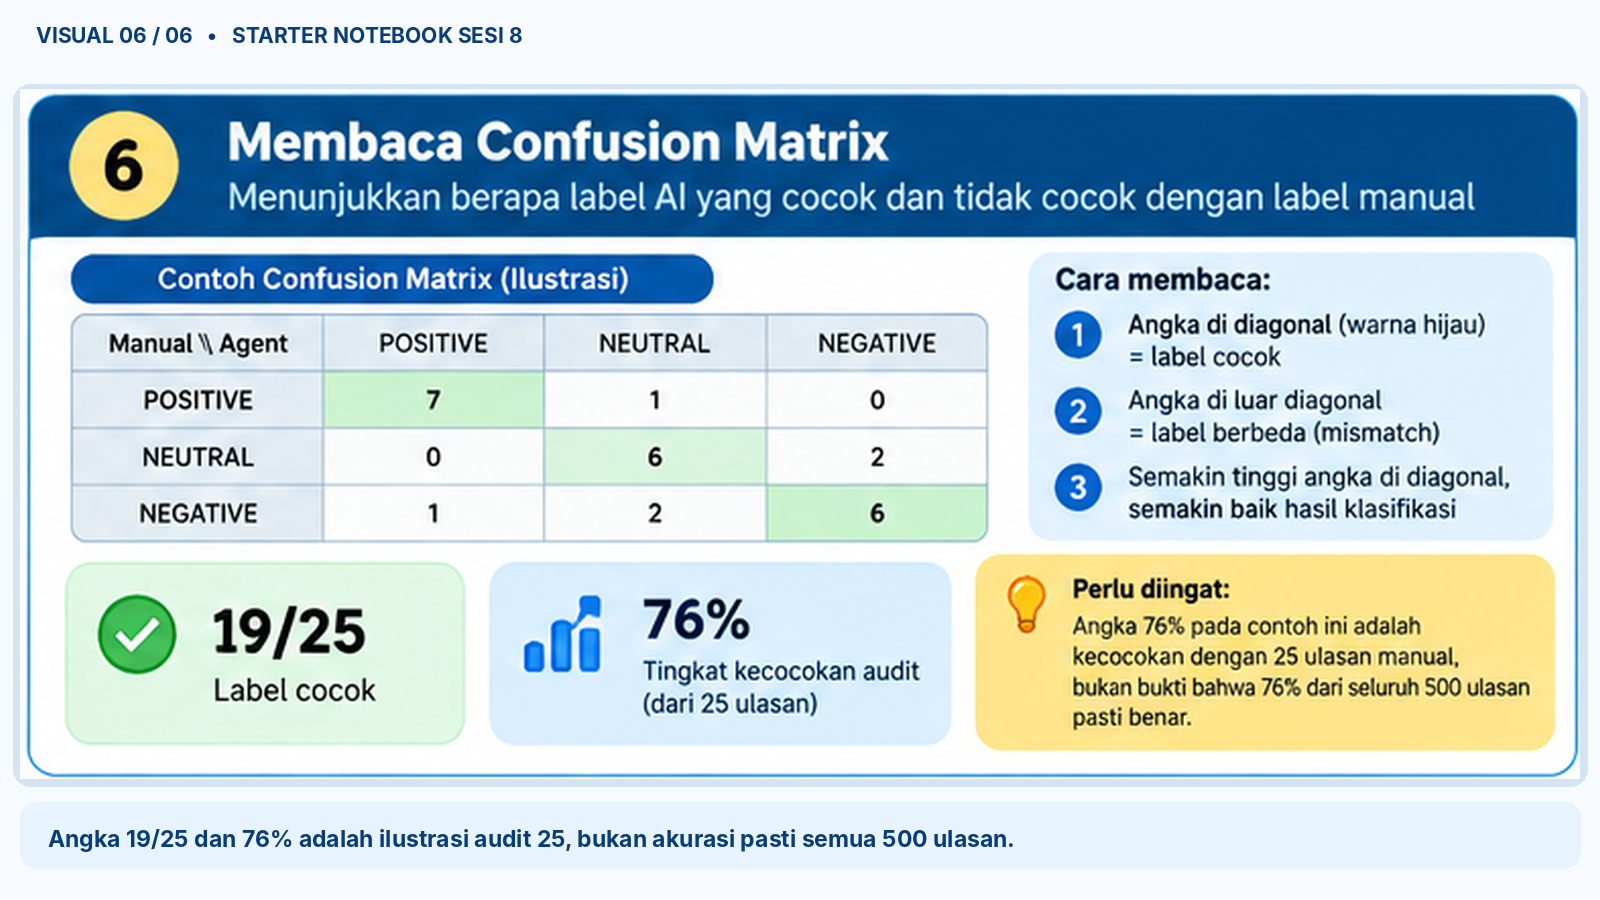

In [13]:
def step_compare():
    require('LANGKAH 08 | Label 500')
    wb=wp_load()
    try:
        original_audit=audit_validate(wb,need_labels=True)
        if audit_snapshot(original_audit)!=ST['AUDIT_SNAPSHOT']:
            stop('Audit manual berubah setelah dikunci. Kembalikan hasil audit independen atau hubungi trainer.')
        ws=wb['02 Hasil Evaluasi']
        ids=[x[0] for x in original_audit]
        lookup=ST['AGENT_LABELS'].set_index('review_id')['agent_label_v1'].to_dict()
        pairs=[(rid,lookup[rid]) for rid in ids]
        for idx,(rid,agent_lab) in enumerate(pairs):
            row=12+idx
            current_id=text(ws[f'AA{row}'].value)
            current_label=label(ws[f'AB{row}'].value)
            if (current_id or current_label) and (current_id!=rid or current_label!=agent_lab):
                stop(f'Sheet 02 AA{row}:AB{row} berisi hasil Agent berbeda. Jangan menimpa data tanpa persetujuan trainer.')
        for idx,(rid,agent_lab) in enumerate(pairs):
            row=12+idx
            ws[f'AA{row}']=rid
            ws[f'AB{row}']=agent_lab
        wb.calculation=CalcProperties(calcMode='auto',fullCalcOnLoad=True,forceFullCalc=True)
        try:
            wb.save(ST['WP_PATH'])
        except (PermissionError, OSError):
            print('CADANGAN: 25 pasangan ID dan label Agent untuk ditempel trainer ke AA12:AB36 pada Sheet 02:')
            display(pd.DataFrame(pairs,columns=['Agent Review ID','Agent Label V1']))
            stop('Working Paper belum dapat disimpan. Cara utama: Save lalu tutup Excel dan Run ulang LANGKAH 09. Cadangan dengan trainer: salin dua kolom tabel di atas ke zona integrasi Sheet 02.')
    finally:wb.close()
    manual=[x[2] for x in original_audit]
    predicted=[x[1] for x in pairs]
    matrix=pd.crosstab(pd.Series(manual,name='Manual'),pd.Series(predicted,name='Agent'))
    matrix=matrix.reindex(index=LABELS,columns=LABELS,fill_value=0)
    matches=sum(a==b for a,b in zip(manual,predicted))
    ST['MATRIX']=matrix
    ST['MATCH_COUNT']=matches
    ST['MISMATCH_IDS']=[rid for (rid,txt,man),pred in zip(original_audit,predicted) if man!=pred]
    ST['PAIRS']=pairs
    ST['AUDIT_MAP']={rid:(raw,man,pred) for (rid,raw,man),pred in zip(original_audit,predicted)}
    print('✅ COMPARISON: READY | 25/25 Review ID valid')
    print(f'Label cocok: {matches}/25 | Match Rate: {matches/25:.0%} | Mismatch: {25-matches}')
    print('Confusion Matrix (baris MANUAL, kolom AGENT):')
    display(matrix)
    print('Contoh ID berbeda:',', '.join(ST['MISMATCH_IDS'][:7]) if ST['MISMATCH_IDS'] else 'Tidak ada pada sampel ini')
    print('Working Paper Sheet 02 diperbarui. Buka kembali Excel untuk melihat formula otomatis setelah perhitungan ulang.')
    print('Jika matrix Excel belum menampilkan angka, di Excel tekan Ctrl+Alt+F9 untuk menghitung ulang rumus, lalu simpan.')
run_step('LANGKAH 09 | Matrix',step_compare)

LANGKAH 09 | Matrix
✅ COMPARISON: READY | 25/25 Review ID valid
Label cocok: 20/25 | Match Rate: 80% | Mismatch: 5
Confusion Matrix (baris MANUAL, kolom AGENT):


Agent,POSITIVE,NEUTRAL,NEGATIVE
Manual,,,
POSITIVE,9,0,0
NEUTRAL,1,7,4
NEGATIVE,0,0,4


Contoh ID berbeda: R0045, R0048, R0115, R0126, R0380
Working Paper Sheet 02 diperbarui. Buka kembali Excel untuk melihat formula otomatis setelah perhitungan ulang.
Jika matrix Excel belum menampilkan angka, di Excel tekan Ctrl+Alt+F9 untuk menghitung ulang rumus, lalu simpan.


### Cara Membaca Confusion Matrix pada Sheet **`02 Hasil Evaluasi`**

**Lihat sel `B13:D15`.** Di Working Paper, **baris** = label menurut kamu (manual), sedangkan **kolom** = label Agent.

- **`B13`, `C14`, `D15`** (diagonal) berarti **cocok**.
- Sel **di luar diagonal** berarti label AI berbeda dengan label manual.
- **`D7`** jumlah yang cocok. **`B8`** proporsi cocok dari **25 sampel**.
- **`B19`** menunjukkan pola perbedaan yang muncul paling sering.

**Contoh ilustrasi:** 19 label cocok dari 25 → `19/25 = 76%`. **Ini bukan hasil nyata kelas** dan **bukan akurasi universal AI pada 500 ulasan**.

**Jangan mengisi atau menghapus rumus di area matrix.** Kerja peserta pada Sheet 02 hanya sel **`B23:B26`**, sesuai instruksi berikut.

## 09. Temukan Satu Kesalahan dan Usulkan Perbaikan — LANGKAH 10

**Kasus:** Kadang Agent membaca “Mantap, paket rusak lagi!” sebagai pujian, padahal itu keluhan sarkastik.

**Tujuan:** Menjelaskan **satu perbedaan yang benar-benar terjadi** dan mencoba memperbaiki aturan, tanpa mengklaim 500 label sudah direvisi.

### Excel mana dan sel apa yang diisi?
1. Buka `S8_NusaMart_Text_Sentiment_Working_Paper.xlsx` → klik tab **`02 Hasil Evaluasi`**.
2. Baca `B19` (pola salah label utama) dan **Review ID yang berbeda** pada output LANGKAH 09 di Notebook.
3. Klik **`B23`** → pilih **satu Review ID berbeda** dari dropdown. **Sumber jawabannya:** daftar mismatch yang ditampilkan Notebook, bukan asal memilih.
4. Klik **`B24`** → tulis **mengapa label Agent berbeda**, misalnya AI terlalu fokus pada kata pujian dan mengabaikan keluhan. **Sumber:** teks ulasan dan label manual versus AI.
5. Klik **`B25`** → tulis **satu aturan yang akan diperbaiki**, misalnya utamakan maksud keseluruhan pada sarkasme.
6. Tekan **Ctrl+S**, **tutup Excel**, lalu kembali ke Notebook dan klik ▶ **Run** pada kode `def step_revision_prompt` (LANGKAH 10).
7. Notebook **membuat prompt uji revisi secara otomatis** dan menampilkannya. **Salin prompt itu ke Agent** untuk menguji teks terpilih (uji terbatas).
8. Baca jawaban Agent, buka kembali Sheet `02 Hasil Evaluasi`, klik **`B26`** → tulis **hasil uji ulang**, misalnya “setelah aturan diperjelas, label menjadi NEGATIVE untuk ulasan terpilih”. **Sumber:** jawaban Agent yang kamu periksa.
9. Tekan **Ctrl+S**, kemudian tutup Excel sebelum Final Check.

**Jika 25 audit tidak menemukan mismatch:** pilih **satu contoh kasus sulit** dari 25 audit dan tulis bahwa belum ditemukan mismatch, lalu lakukan uji kejelasan aturan. **Jangan mengarang kesalahan.**

**Hasil yang diharapkan:** `PROMPT UJI REVISI: SIAP`, lalu **`B23:B26`** terisi setelah pengujian.

**Apa artinya?** Kamu mencoba memperbaiki satu kasus. **Label 500 ulasan pada CSV final tetap V1** karena tidak ada klasifikasi ulang seluruh dataset.

**Lanjut:** LANGKAH 11 — Final Check.

### LANGKAH 10 — Jalankan Prompt Uji Perbaikan

**Apa yang kamu lakukan?** Pastikan Excel Sheet `02 Hasil Evaluasi`: **`B23`** (Review ID), **`B24`** (alasan), **`B25`** (usulan aturan) sudah terisi. Simpan Excel, lalu klik ▶ **Run** pada kode tepat di bawah ini (dimulai `def step_revision_prompt`).

**Apa hasilnya?** Notebook menampilkan `PROMPT UJI REVISI: SIAP` dan teks prompt baru. **Notebook belum menjalankan AI.** Kamu harus menyalin prompt ke chat Antigravity, lalu **Send**.

**Setelah Agent menjawab:** baca hasil, isi **`B26`** pada Sheet `02 Hasil Evaluasi`, lalu **Ctrl+S** dan tutup Excel.

**Lanjut:** LANGKAH 11 — Final Check dan Export.

In [17]:
def step_revision_prompt():
    require('LANGKAH 09 | Matrix')
    wb=wp_load()
    try:
        ws=wb['02 Hasil Evaluasi']
        rid=text(ws['B23'].value)
        why=text(ws['B24'].value)
        revision=text(ws['B25'].value)
    finally:wb.close()
    if not rid or not why or not revision:
        stop('Sheet 02 belum lengkap. Isi B23 (Review ID), B24 (Mengapa berbeda), B25 (Aturan diperbaiki), lalu Save. Hasil uji B26 diisi SETELAH mencoba prompt.')
    if rid not in ST['AUDIT_MAP']:
        stop('Review ID di Sheet 02 B23 tidak ada dalam 25 sampel audit. Pilih melalui dropdown.')
    if ST['MISMATCH_IDS'] and rid not in ST['MISMATCH_IDS']:
        stop('Masih ada mismatch, tetapi B23 bukan ID mismatch. Pilih salah satu ID berbeda: '+', '.join(ST['MISMATCH_IDS'][:12]))
    if len(why)<10 or len(revision)<10:
        stop('Isi alasan perbedaan dan aturan revisi dengan masing-masing minimal satu kalimat pendek yang jelas.')
    raw,manual,agent=ST['AUDIT_MAP'][rid]
    prompt=f'''Uji TERBATAS satu usulan perbaikan aturan sentimen pada teks pelanggan berikut.
Jangan mengubah file sumber atau hasil 500 label V1.

TEKS: {raw}
REVIEW ID: {rid}
LABEL MANUAL (pembanding): {manual}
LABEL AGENT V1: {agent}
ALASAN PERBEDAAN: {why}
USULAN REVISI ATURAN: {revision}

Tentukan label baru berdasarkan usulan revisi, pilih hanya POSITIVE / NEUTRAL / NEGATIVE.
Jelaskan alasan yang merujuk isi teks, bukan hanya satu kata.
Tunjukkan label sebelum dan sesudah serta apakah revisi memperbaiki contoh ini.
Jangan menyatakan 500 label sudah direvisi. Ini hanya pemeriksaan terbatas.'''
    print('✅ PROMPT UJI REVISI: SIAP')
    print('Review ID:',rid,'| Manual:',manual,'| Agent V1:',agent)
    print('\n--- SALIN PROMPT KE ANTIGRAVITY ---\n'+prompt+'\n--- AKHIR PROMPT ---')
    print('Setelah Agent menjawab, isi Sheet 02 sel B26 (Hasil uji ulang), Save, lalu LANGKAH 11.')
run_step('LANGKAH 10 | Revisi',step_revision_prompt)

LANGKAH 10 | Revisi
✅ PROMPT UJI REVISI: SIAP
Review ID: R0048 | Manual: NEUTRAL | Agent V1: NEGATIVE

--- SALIN PROMPT KE ANTIGRAVITY ---
Uji TERBATAS satu usulan perbaikan aturan sentimen pada teks pelanggan berikut.
Jangan mengubah file sumber atau hasil 500 label V1.

TEKS: CS ramah, tetapi waktu responsnya cukup lama...
REVIEW ID: R0048
LABEL MANUAL (pembanding): NEUTRAL
LABEL AGENT V1: NEGATIVE
ALASAN PERBEDAAN: Agent lebih mengabaikan pelayanan kurir yang bersikap ramah dan hanya fokus pada keluhan
USULAN REVISI ATURAN: gunakan dominansi; bila ulasan terlihat seimbang NEUTRAL

Tentukan label baru berdasarkan usulan revisi, pilih hanya POSITIVE / NEUTRAL / NEGATIVE.
Jelaskan alasan yang merujuk isi teks, bukan hanya satu kata.
Tunjukkan label sebelum dan sesudah serta apakah revisi memperbaiki contoh ini.
Jangan menyatakan 500 label sudah direvisi. Ini hanya pemeriksaan terbatas.
--- AKHIR PROMPT ---
Setelah Agent menjawab, isi Sheet 02 sel B26 (Hasil uji ulang), Save, lalu LANGK

## 10. FINAL CHECK & Simpan Hasil — LANGKAH 11

**Kasus:** NusaMart membutuhkan dataset sentimen yang lengkap dan bukti bahwa hasil AI pernah diaudit.

**Tujuan:** Memastikan dua file hasil praktik bisa dipakai dan dikumpulkan tanpa mengirim file sementara.

### Langkah terakhir, bersama trainer
1. Buka Working Paper → tab **`01 Audit 25`**, periksa **`C7 = AUDIT: READY`**.
2. Klik tab **`02 Hasil Evaluasi`**, periksa **`D8 = COMPARISON: READY`**, Confusion Matrix terhitung, dan **`B23:B26` sudah terisi**.
3. Tekan **Ctrl+S**, lalu **tutup file Excel**.
4. Di Notebook, klik ▶ **Run** pada cell kode tepat di bawah instruksi ini (dimulai `def step_final`).
5. Tunggu `FINAL CHECK: LOLOS`. Jika STOP, kembali ke sel yang disebut dalam pesan, Save, lalu Run ulang langkah terkait.
6. Buka `practice/sesi_08/outputs/sesi_08/` dan pastikan **`nusamart_reviews_labeled_s8.csv`** ada.
7. **Kumpulkan langsung 2 file ke LMS, tidak perlu ZIP:**
   - `nusamart_reviews_labeled_s8.csv` (500 label sentimen V1, untuk S9)
   - `S8_NusaMart_Text_Sentiment_Working_Paper.xlsx` (**2 sheet** dengan audit dan evaluasi)

**Jangan kumpulkan** `agent_input_v1.csv`, `agent_labels_v1.csv`, TXT prompt, screenshot, atau Starter kosong.

**Apa arti LOLOS?** Struktur data dan evidence wajib lengkap. **LOLOS tidak membuktikan AI benar pada semua 500 ulasan.**

In [19]:
def step_final():
    require('LANGKAH 10 | Revisi')
    if sha(ST['SOURCE_PATH'])!=ST['SOURCE_SHA']:
        stop('CSV sumber berubah sejak INPUT GATE. Kembalikan dataset asli dari LMS dan mulai dari LANGKAH 03.')
    if sha(ST['OUT_DIR']/'agent_labels_v1.csv')!=ST['LABEL_FILE_SHA']:
        stop('File label Agent berubah sejak validasi. Ulangi LANGKAH 08 dan LANGKAH 09 sebelum mengekspor.')
    wb=wp_load()
    try:
        audit_now=audit_validate(wb,need_labels=True)
        if audit_snapshot(audit_now)!=ST['AUDIT_SNAPSHOT']:
            stop('25 label manual berubah setelah dikunci. Jangan mengganti hasil audit berdasarkan hasil AI.')
        ws=wb['02 Hasil Evaluasi']
        for idx,(rid,lab) in enumerate(ST['PAIRS']):
            row=12+idx
            if text(ws[f'AA{row}'].value)!=rid or label(ws[f'AB{row}'].value)!=lab:
                stop(f'Zona integrasi Sheet 02 AA{row}:AB{row} berbeda dari hasil Agent yang diverifikasi. Ulangi LANGKAH 09.')
        fields={key:text(ws[key].value) for key in ['B23','B24','B25','B26']}
        missing=[key for key,value in fields.items() if not value]
        if missing:stop('Sheet 02 belum lengkap: '+', '.join(missing)+'. Isi evaluasi dan hasil uji ulang, lalu Save.')
        if fields['B23'] not in ST['AUDIT_MAP']:
            stop('Review ID evaluasi B23 bukan bagian dari 25 ulasan audit.')
        if ST['MISMATCH_IDS'] and fields['B23'] not in ST['MISMATCH_IDS']:
            stop('B23 harus memilih satu ID yang berbeda jika mismatch ditemukan.')
        if any(len(fields[k])<10 for k in ['B24','B25','B26']):
            stop('B24, B25, dan B26 perlu penjelasan singkat yang bermakna, bukan satu kata.')
        # Rumus tetap dipertahankan dalam Working Paper, pemeriksaan angka dilakukan ulang di Notebook.
        formula_cells=['B13','C13','D13','B14','C14','D14','B15','C15','D15','D8','D16','AC12','AC36']
        absent=[cell for cell in formula_cells if ws[cell].data_type!='f']
        if absent:stop('Rumus Working Paper hilang di Sheet 02: '+', '.join(absent)+'. Gunakan template asli dari LMS.')
    finally:wb.close()
    w=ST['LABELED'].copy()
    if len(w)!=500 or w['review_id'].nunique()!=500 or w['agent_label_v1'].isna().any():
        stop('Jumlah label bukan 500/500. Ulangi validasi pada LANGKAH 08.')
    if not w['original_text'].equals(ST['SOURCE']['original_text']):
        stop('Original Text tidak identik dengan dataset asli. Jangan ekspor.')
    if sum(int(x) for x in ST['MATRIX'].to_numpy().ravel())!=25:
        stop('Jumlah sel Confusion Matrix tidak sama dengan 25. Ulangi LANGKAH 09.')
    w['sentiment_label']=w['agent_label_v1']
    w['label_version']='V1'
    w['coding_scheme_version']=ST['RULES_VERSION']
    w['fewshot_version']=ST['FEWSHOT_VERSION']
    w['audit_scope']='25 manual sample, not full validation'
    audit_set={x[0] for x in ST['AUDIT']}
    w['was_manually_audited']=w['review_id'].isin(audit_set)
    final=ST['OUT_DIR']/'nusamart_reviews_labeled_s8.csv'
    w.to_csv(final,index=False,encoding='utf-8-sig')
    test=pd.read_csv(final,dtype={'review_id':'string'},keep_default_na=False,encoding='utf-8-sig')
    if len(test)!=500 or test['review_id'].nunique()!=500 or not test['sentiment_label'].isin(LABELS).all():
        stop('Ekspor CSV final gagal verifikasi. Tunjukkan kendala kepada trainer.')
    print('✅ FINAL CHECK: LOLOS')
    display(pd.DataFrame({'Pemeriksaan':['Dataset sumber','Coding Scheme standar + Few-Shot','Labeling AI','Audit manual independen','Confusion Matrix','Evaluasi + revisi terbatas','Ekspor final CSV'],
      'Hasil':['PASS','PASS','500/500 PASS','25/25 PASS','25/25 PASS','COMPLETE','PASS']}))
    print('CSV FINAL:',final)
    print('WORKING PAPER:',ST['WP_PATH'])
    print('Dataset menggunakan label V1 untuk seluruh 500 ulasan. Perbaikan aturan baru diuji terbatas di Sheet 02.')
    print('KUMPULKAN DUA FILE DI ATAS. Tidak perlu ZIP atau file perantara.')
run_step('LANGKAH 11 | Final',step_final)

LANGKAH 11 | Final
✅ FINAL CHECK: LOLOS


,Pemeriksaan,Hasil
0,Dataset sumber,PASS
1,Coding Scheme standar + Few-Shot,PASS
2,Labeling AI,500/500 PASS
3,Audit manual independen,25/25 PASS
4,Confusion Matrix,25/25 PASS
5,Evaluasi + revisi terbatas,COMPLETE
6,Ekspor final CSV,PASS


CSV FINAL: C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_08\outputs\sesi_08\nusamart_reviews_labeled_s8.csv
WORKING PAPER: C:\Bootcamp\Bootcamp_Data_Analyst\practice\sesi_08\S8_NusaMart_Text_Sentiment_Working_Paper.xlsx
Dataset menggunakan label V1 untuk seluruh 500 ulasan. Perbaikan aturan baru diuji terbatas di Sheet 02.
KUMPULKAN DUA FILE DI ATAS. Tidak perlu ZIP atau file perantara.


### Jika Muncul STOP: yang harus diperbaiki (tidak perlu mengedit kode)

| Pesan | Tindakan peserta |
|---|---|
| File CSV/Excel tidak ditemukan | Pastikan `reviews_500.csv` dan Working Paper versi **2 sheet** ada di `practice/sesi_08/`. |
| Dataset bukan 500 atau ID tidak unik | Gunakan kembali CSV asli dari LMS, jangan menghapus/mengganti baris. |
| Pemeriksaan Coding Scheme salah | Baca kasus sarkasme pada **Bagian 04**, lalu jawab pertanyaan LANGKAH 05 kembali. |
| `MANUAL AUDIT` belum 25/25 | Di Sheet **01 Audit 25**, isi dropdown yang belum lengkap pada **C12:C36**. Ctrl+S lalu Run ulang LANGKAH 06. |
| Audit berubah setelah dikunci | **Jangan menyesuaikan label dengan AI**. Tampilkan masalah kepada trainer. |
| File `agent_labels_v1.csv` belum ada | Buka panel Agent, kirim prompt, periksa benar-benar ada file di `outputs/sesi_08/`. |
| Agent hanya menghasilkan 499 baris / label ilegal | Minta Agent menyelesaikan atau memperbaiki hasil. Jangan mengedit dataset sumber. |
| Confusion Matrix tidak muncul di Excel | Pastikan LANGKAH 09 READY, lalu **Formulas → Calculate Now**. |
| `B23:B26` kosong | Di Sheet **02 Hasil Evaluasi**, isi Review ID, alasan, revisi, dan hasil uji Agent. |
| Working Paper tidak dapat ditulis | Save dan tutup Excel, lalu Run ulang LANGKAH 09. |
| Final Check belum LOLOS | Baca bagian yang masih STOP; perbaiki **hanya** langkah itu, bukan mulai ulang semuanya. |

**Minta bantuan trainer dengan menyebut LANGKAH, pesan STOP, dan nama file.**

## Penutup: Apa yang Sudah Kamu Kerjakan?

- Dari **Sesi 7**, kamu sudah belajar: temuan angka harus **didukung bukti dan diuji ulang**.
- Pada **Sesi 8**, kamu menerapkan prinsip yang sama untuk **500 label sentimen hasil AI Agent**.
- Kamu **menerapkan Coding Scheme dan Few-Shot standar** (S8-CS-01, S8-FS-01), melakukan **audit manual 25 ulasan**, membaca **Confusion Matrix**, dan mencoba **satu perbaikan aturan**.
- **Sesi 9** dapat menggunakan `nusamart_reviews_labeled_s8.csv` untuk menampilkan evidence sentimen di dashboard, dengan catatan **hanya 25 label yang dibandingkan manual**.

### Hasil yang dikumpulkan
1. **CSV berlabel** 500 review dari hasil klasifikasi penuh V1.
2. **Working Paper 2 sheet** yang terisi dan tersimpan.

**Penting:** Jika belum LOLOS, lanjutkan dengan pendampingan trainer sesuai arahan kelas. Jangan menyebut label simulasi atau hasil fallback sebagai hasil Agent nyata.

**Selamat, kamu telah menyelesaikan latihan memeriksa AI menggunakan evidence, bukan sekadar menekan tombol Run.**